In [15]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt




My plan for this exploration is simply to use alivestreets to:

<ol>
<li>Get the street network (with OSMnX).</li>
<li>Sample the street network.</li>
<li>Retrieve metadata at each location (which is free).</li>
<li>Get distributions of where images are missing. </li>
</ol>

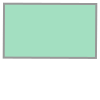

In [16]:
##
RECTANGLE_AREA_PATH = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/spatial/bounding_box.geojson"

gdf = gpd.read_file(RECTANGLE_AREA_PATH)

gdf_lat_lon = gdf.to_crs("EPSG:4326")
polygon = gdf_lat_lon["geometry"][0]

polygon

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_07_21_imagery_and_weather_station_data_exploration/street_network.geojson


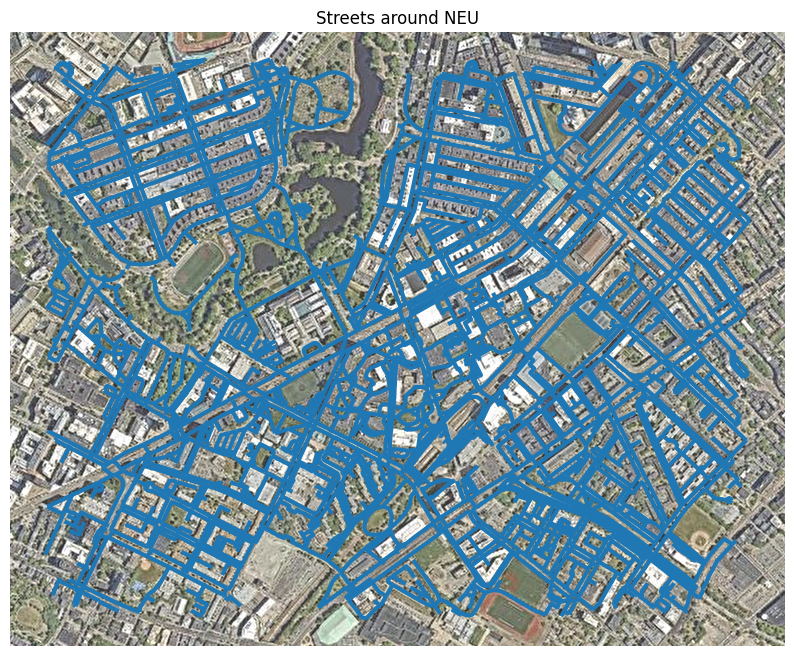

In [23]:
from alivestreets.network.network_retrieval import (
    get_graph_from_point,
    get_graph_from_polygon,
    graph_to_dataframe,
    export_graph_geojson,
)


graph = get_graph_from_polygon(
    polygon
)

gdf_streets = graph_to_dataframe(graph)

EXPORT_PATH_STREET_NETWORK = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_07_21_imagery_and_weather_station_data_exploration/street_network.geojson"

#First let's save it and then we can visualize. 
export_graph_geojson(
    graph,
    EXPORT_PATH_STREET_NETWORK
)

from alivestreets.visualization.map_visualizer import MapVisualizer

map_visualizer = MapVisualizer()
map_visualizer.initialize_map(figsize = (10,10))

gdf_web = gdf_streets.to_crs("EPSG:3857")
gdf_web.plot(
    ax = map_visualizer.ax,
    linewidth = 3
)

map_visualizer.add_basemap(
    alpha = 0.8,
    tile_url=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    )
    )
map_visualizer.finalize_map(title = "Streets around NEU")




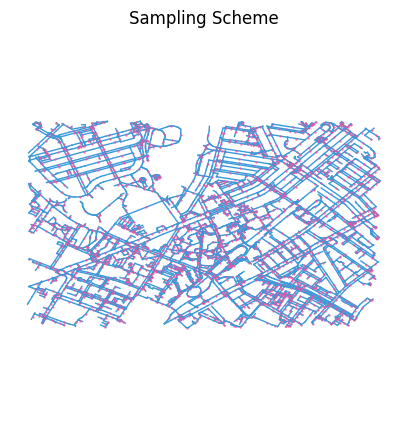

In [33]:
from alivestreets.sampling.street_sampler import StreetSampler

sampled_points = 1000
sampler = StreetSampler(sampled_points)

sampler.open_streets(EXPORT_PATH_STREET_NETWORK)

sampler.sample_streets_no_intersections()

sampler.draw_sampling_scheme(
    node_size = 0.5,
    width = 5, 
    height = 5
)



### Street View coverage. 

In [41]:
MAPS_API_KEY = ""

from alivestreets.streetview_collection.streetview_collection import (
    StreetViewImageCollector,
)
from tqdm import tqdm 

collector = StreetViewImageCollector(api_key=MAPS_API_KEY)
points = sampler.get_all_sampling_points()
metadata_dictionaries = []
for i in tqdm(range(0,len(points))):
    point = points[i]
    longitude = point[0]
    latitude = point[1]

    metadata = collector.fetch_street_view_metadata(
        lat = point[1], 
        lon = point[0]
    )

    metadata_dictionaries.append(metadata)
    

100%|██████████| 3167/3167 [16:36<00:00,  3.18it/s]


In [43]:
import json
EXPORT_IMAGE_METADATA_DICTIONARIES = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_07_21_imagery_and_weather_station_data_exploration/metadata_dictionaries.json"
with open(EXPORT_IMAGE_METADATA_DICTIONARIES, "w") as f:
    json.dump(metadata_dictionaries, f, indent=4)

In [46]:
image_coverage = []
for i in range(0,len(metadata_dictionaries)):
    metadata_dictionary = metadata_dictionaries[i]
    status = metadata_dictionary["status"]
    if(status == "OK"):
        image_coverage.append(1)
    else:
        image_coverage.append(0)


print(sum(image_coverage)/len(image_coverage))

0.9930533628039154


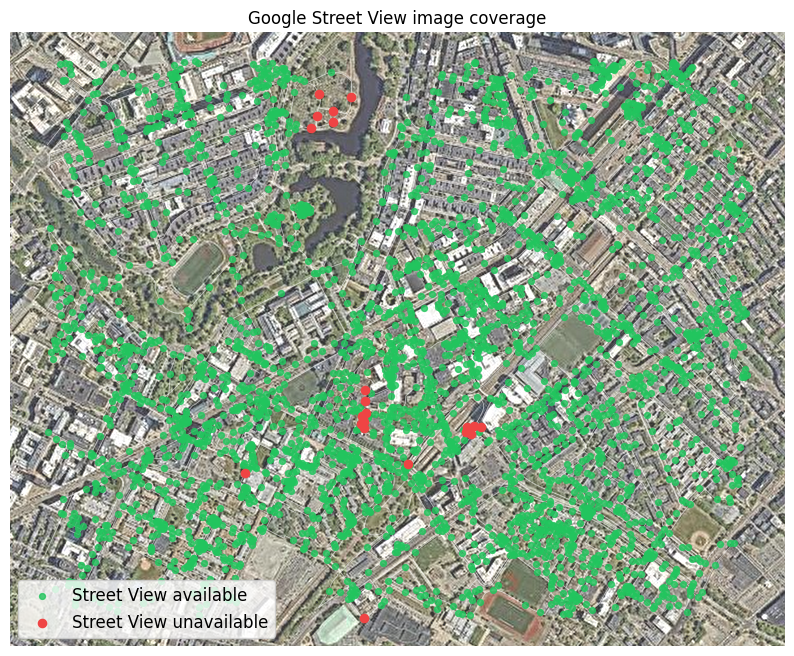

Available: 3,145
Unavailable: 22


In [47]:
# Visualize Street View availability at every sampled point.
available_points = [
    point for point, available in zip(points, image_coverage) if available == 1
]
unavailable_points = [
    point for point, available in zip(points, image_coverage) if available == 0
]

coverage_map = MapVisualizer()
coverage_map.initialize_map(figsize=(10, 10))

# Draw the street network as geographic context.
gdf_streets.to_crs("EPSG:3857").plot(
    ax=coverage_map.ax,
    color="white",
    linewidth=0.7,
    alpha=0.55,
    zorder=2,
)

if available_points:
    coverage_map.add_points(
        points=available_points,
        weights=[1] * len(available_points),
        color="#22c55e",
        min_size=18,
        max_size=18,
        alpha=0.8,
        label_family="Street View available",
    )

if unavailable_points:
    coverage_map.add_points(
        points=unavailable_points,
        weights=[1] * len(unavailable_points),
        color="#ef4444",
        min_size=35,
        max_size=35,
        alpha=1.0,
        label_family="Street View unavailable",
    )

coverage_map.add_basemap(
    alpha=0.8,
    tile_url=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
)
coverage_map.finalize_map(
    title="Google Street View image coverage",
    show_legend=True,
)

print(f"Available: {len(available_points):,}")
print(f"Unavailable: {len(unavailable_points):,}")